Hücre 1: Kütüphanelerimportlar

In [1]:

import time
import warnings


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, TargetEncoder 
from sklearn.impute import SimpleImputer


from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor 


from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


warnings.filterwarnings('ignore')
%matplotlib inline
pd.set_option('display.float_format', lambda x: '%.2f' % x)

Hücre 2: Veri Yükleme ve Ön İşleme

In [2]:
# Veriyi yükle
df = pd.read_csv('Property Sales of Melbourne City.csv')


# Tarih sütununu işleyelim. 2 yıllık bir verimiz var ev satışlarında bazı aylarda satış miktarı arttığı için aylara ayıralım
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df['Sale_Month'] = df['Date'].dt.month.astype(str) 

# Gereksiz sütunları temizleme
cols_to_drop = ['Address', 'Date', 'Lattitude', 'Longtitude', 'Postcode', 'SellerG','Unnamed: 0'] 
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns], errors='ignore')

#Aykırı değer (Outlier) temizliği
def remove_outliers_iqr(df, columns):
    df_clean = df.copy()
    for col in columns:
        Q1 = df_clean[col].quantile(0.05)
        Q3 = df_clean[col].quantile(0.95)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df_clean[col] = df_clean[col].clip(lower=lower, upper=upper)
    return df_clean

numeric_cols = ['Price', 'Landsize', 'BuildingArea', 'Distance']
cols_present = [c for c in numeric_cols if c in df.columns]
df = remove_outliers_iqr(df, cols_present)

#Eksik Veri Doldurma
num_cols = df.select_dtypes(include=[np.number]).columns
cat_cols = df.select_dtypes(include=['object']).columns

# Sayısal olanlarda medyan kullanalım
imp_num = SimpleImputer(strategy='median')
df[num_cols] = imp_num.fit_transform(df[num_cols])

# Kategorik olanlarda mod kullanalım
imp_cat = SimpleImputer(strategy='most_frequent')
df[cat_cols] = imp_cat.fit_transform(df[cat_cols])

# DataFrame formatını koruyalım
df = pd.DataFrame(df, columns=num_cols.append(cat_cols))

print("Veri Ön İşleme Tamamlandı.")

Veri Ön İşleme Tamamlandı.


Hücre 3: Encoding, Split ve Scaling

In [3]:
# 1. Değişkenleri Ayırma
X = df.drop('Price', axis=1)

# Hedef değişkeni sayıya çevirme (Hata önleyici)
try:
    y = df['Price'].astype(float)
except ValueError:
    y = df['Price'].astype(str).str.replace(',', '').astype(float)

# 2. Sütun Tespiti
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
# Çok sınıflılarda Target Encoding, Az sınıflılarda One-Hot kullanalım
target_cols = [c for c in categorical_cols if X[c].nunique() > 10]
one_hot_cols = [c for c in categorical_cols if X[c].nunique() <= 10]
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Target Encoding
if target_cols:
    t_encoder = TargetEncoder(smooth="auto", random_state=42, target_type="continuous")
    X_train_target = pd.DataFrame(t_encoder.fit_transform(X_train[target_cols], y_train),
                                  columns=[f"{c}_enc" for c in target_cols], index=X_train.index)
    X_test_target = pd.DataFrame(t_encoder.transform(X_test[target_cols]),
                                 columns=[f"{c}_enc" for c in target_cols], index=X_test.index)
else:
    X_train_target, X_test_target = pd.DataFrame(), pd.DataFrame()

# One-Hot Encoding
if one_hot_cols:
    X_train_oh = pd.get_dummies(X_train[one_hot_cols], drop_first=True)
    X_test_oh = pd.get_dummies(X_test[one_hot_cols], drop_first=True)
    X_train_oh, X_test_oh = X_train_oh.align(X_test_oh, join='left', axis=1, fill_value=0)
else:
    X_train_oh, X_test_oh = pd.DataFrame(), pd.DataFrame()

# Birleştirme
X_train_final = pd.concat([X_train[num_cols], X_train_oh, X_train_target], axis=1).astype(float)
X_test_final = pd.concat([X_test[num_cols], X_test_oh, X_test_target], axis=1).astype(float)

# Standardizasyon
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_final), columns=X_train_final.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_final), columns=X_test_final.columns)

print(f"Hazırlık Tamam. Eğitim Seti: {X_train_scaled.shape}")

Hazırlık Tamam. Eğitim Seti: (14716, 25)


Hücre 4: Değerlendirme fonksiyonu (model eğitimleri sonrası tekrar kullanmak için)

In [4]:
def evaluate_regression_performance(model_name, model, X_test_data, y_test, time_taken, 
                                    best_params=None, result_dict=None, plot_color='blue'):
    y_pred = model.predict(X_test_data)
    
    # Metrikler
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    # Raporlama
    is_opt = best_params is not None
    prefix = "OPTIMIZED " if is_opt else ""
    print(f"\n{'='*70}\n{prefix}MODEL RAPORU: {model_name.upper()}\n{'='*70}")
    if is_opt: print(f"En İyi Parametreler: {best_params}\n")
    
    print(f"┌{'─'*25}┬{'─'*15}┐")
    print(f"│ {'Metrik':<23} │ {'Değer':<13} │")
    print(f"├{'─'*25}┼{'─'*15}┤")
    print(f"│ {'İşlem Süresi (sn)':<23} │ {time_taken:<13.4f} │")
    print(f"│ {'R2 Score':<23} │ {r2:<13.4f} │")
    print(f"│ {'MAE (Mutlak Hata)':<23} │ {mae:<13.2f} │") 
    print(f"│ {'RMSE (Karekök Hata)':<23} │ {rmse:<13.2f} │")
    print(f"└{'─'*25}┴{'─'*15}┘\n")
    
    # Grafikler
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    
    # Gerçek vs Tahmin
    ax[0].scatter(y_test, y_pred, alpha=0.5, color=plot_color, edgecolor='k')
    min_val, max_val = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
    ax[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=3)
    ax[0].set_title(f'{model_name}: Gerçek vs Tahmin')
    ax[0].set_xlabel('Gerçek')
    ax[0].set_ylabel('Tahmin')
    
   
    sns.histplot(y_test - y_pred, kde=True, ax=ax[1], color=plot_color)
    ax[1].set_title(f'{model_name}: Hata Dağılımı')
    
    plt.tight_layout()
    plt.show()

    if result_dict is not None:
        result_dict[model_name] = {'R2 Score': r2, 'RMSE': rmse, 'MAE': mae, 'Süre': time_taken}

Hücre 5: 3 Farklı Model Eğitimi

>>> 1. Linear Regression

MODEL RAPORU: LINEAR REGRESSION
┌─────────────────────────┬───────────────┐
│ Metrik                  │ Değer         │
├─────────────────────────┼───────────────┤
│ İşlem Süresi (sn)       │ 0.0081        │
│ R2 Score                │ 0.6533        │
│ MAE (Mutlak Hata)       │ 245171.23     │
│ RMSE (Karekök Hata)     │ 370923.92     │
└─────────────────────────┴───────────────┘



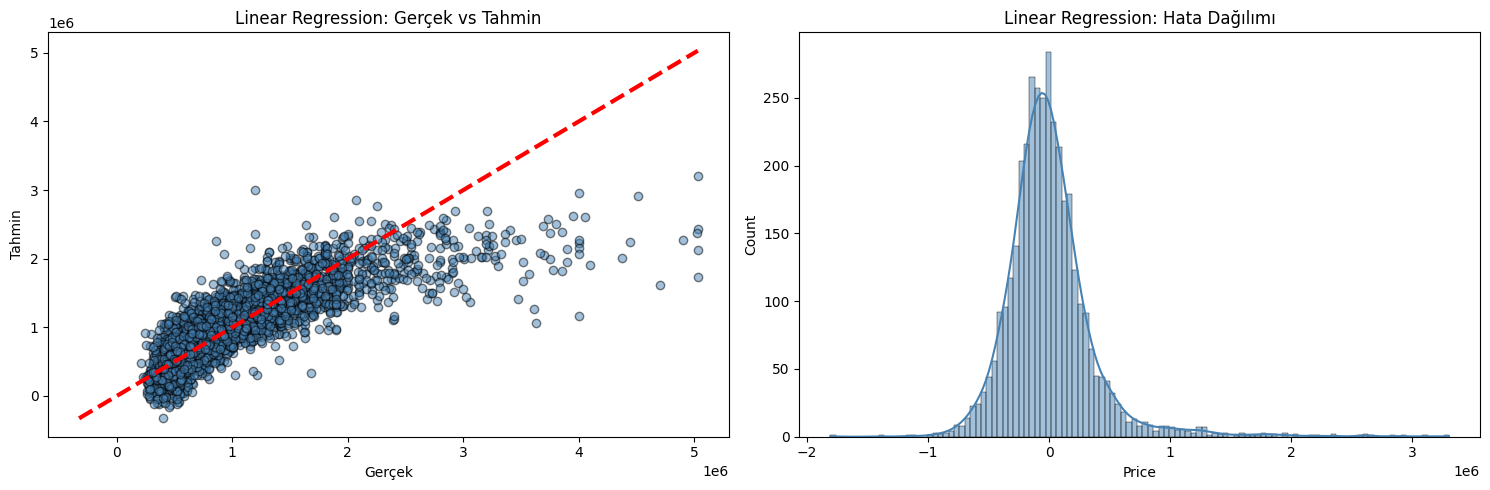


>>> 2. Random Forest

MODEL RAPORU: RANDOM FOREST
┌─────────────────────────┬───────────────┐
│ Metrik                  │ Değer         │
├─────────────────────────┼───────────────┤
│ İşlem Süresi (sn)       │ 7.0295        │
│ R2 Score                │ 0.7783        │
│ MAE (Mutlak Hata)       │ 177389.34     │
│ RMSE (Karekök Hata)     │ 296616.89     │
└─────────────────────────┴───────────────┘



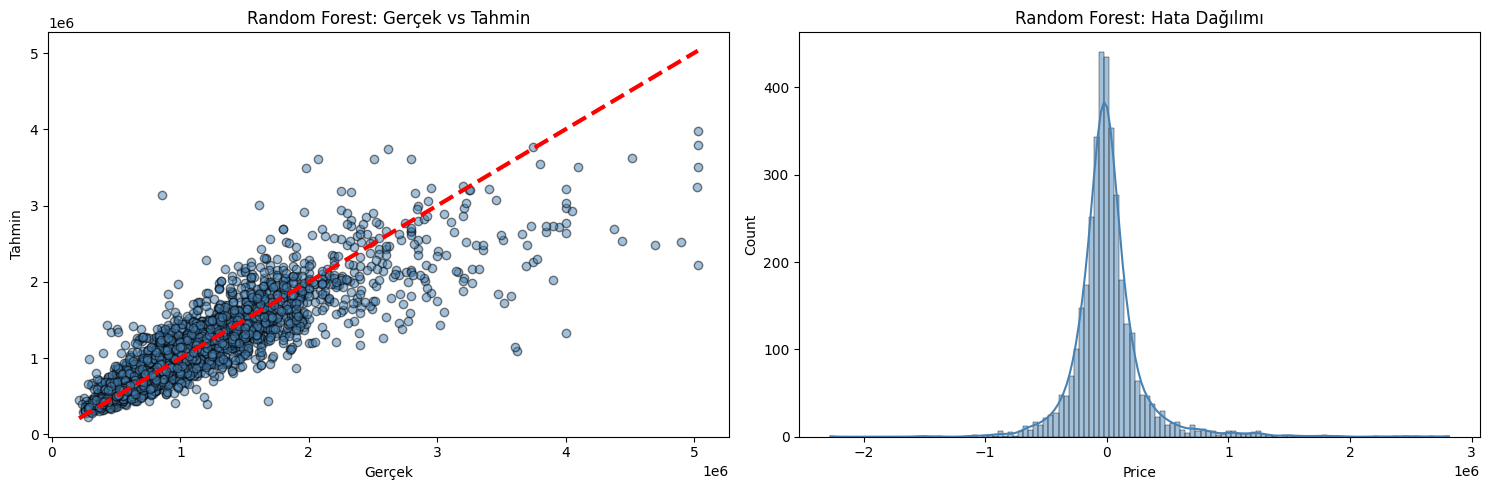


>>> 3. Gradient Boosting

MODEL RAPORU: GRADIENT BOOSTING
┌─────────────────────────┬───────────────┐
│ Metrik                  │ Değer         │
├─────────────────────────┼───────────────┤
│ İşlem Süresi (sn)       │ 1.6927        │
│ R2 Score                │ 0.7618        │
│ MAE (Mutlak Hata)       │ 188105.25     │
│ RMSE (Karekök Hata)     │ 307457.29     │
└─────────────────────────┴───────────────┘



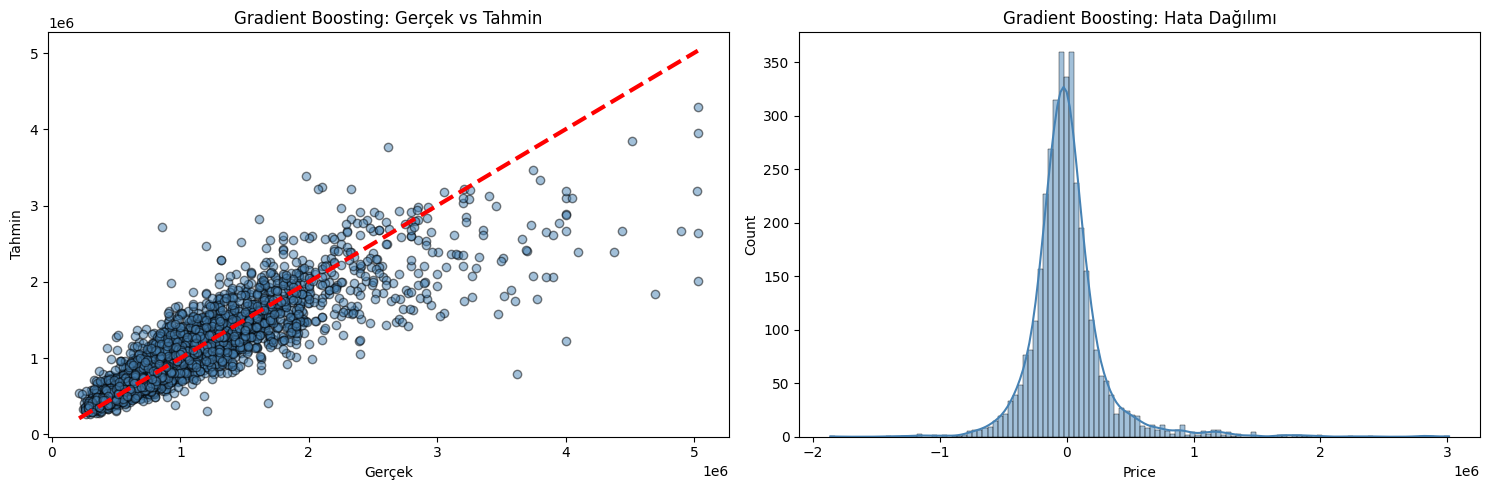


=== TEMEL MODEL SONUÇLARI ===
                   R2 Score      RMSE       MAE  Süre
Random Forest          0.78 296616.89 177389.34  7.03
Gradient Boosting      0.76 307457.29 188105.25  1.69
Linear Regression      0.65 370923.92 245171.23  0.01


In [5]:
base_results = {}

# Linear Regression
print(">>> 1. Linear Regression")
start = time.time()
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
lr_time = time.time() - start
evaluate_regression_performance("Linear Regression", lr, X_test_scaled, y_test, lr_time, 
                                result_dict=base_results, plot_color='steelblue')

# Random Forest
print("\n>>> 2. Random Forest")
start = time.time()
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)
rf_time = time.time() - start
evaluate_regression_performance("Random Forest", rf, X_test_scaled, y_test, rf_time, 
                                result_dict=base_results, plot_color='steelblue')

# Gradient Boosting
print("\n>>> 3. Gradient Boosting")
start = time.time()
gb_reg = GradientBoostingRegressor(n_estimators=100, random_state=42)
gb_reg.fit(X_train_scaled, y_train)
gb_time = time.time() - start
evaluate_regression_performance("Gradient Boosting", gb_reg, X_test_scaled, y_test, gb_time, 
                                result_dict=base_results, plot_color='steelblue')

# Özet tablosu
print("\n=== TEMEL MODEL SONUÇLARI ===")
print(pd.DataFrame(base_results).T.sort_values(by='R2 Score', ascending=False))

Hücre 6: Hiperparametre Optimizasyonu (GridSearchCV)

>>> 1. Random Forest GridSearch

OPTIMIZED MODEL RAPORU: RANDOM FOREST (OPT)
En İyi Parametreler: {'max_depth': 20, 'n_estimators': 100}

┌─────────────────────────┬───────────────┐
│ Metrik                  │ Değer         │
├─────────────────────────┼───────────────┤
│ İşlem Süresi (sn)       │ 21.4834       │
│ R2 Score                │ 0.7799        │
│ MAE (Mutlak Hata)       │ 176801.93     │
│ RMSE (Karekök Hata)     │ 295561.17     │
└─────────────────────────┴───────────────┘



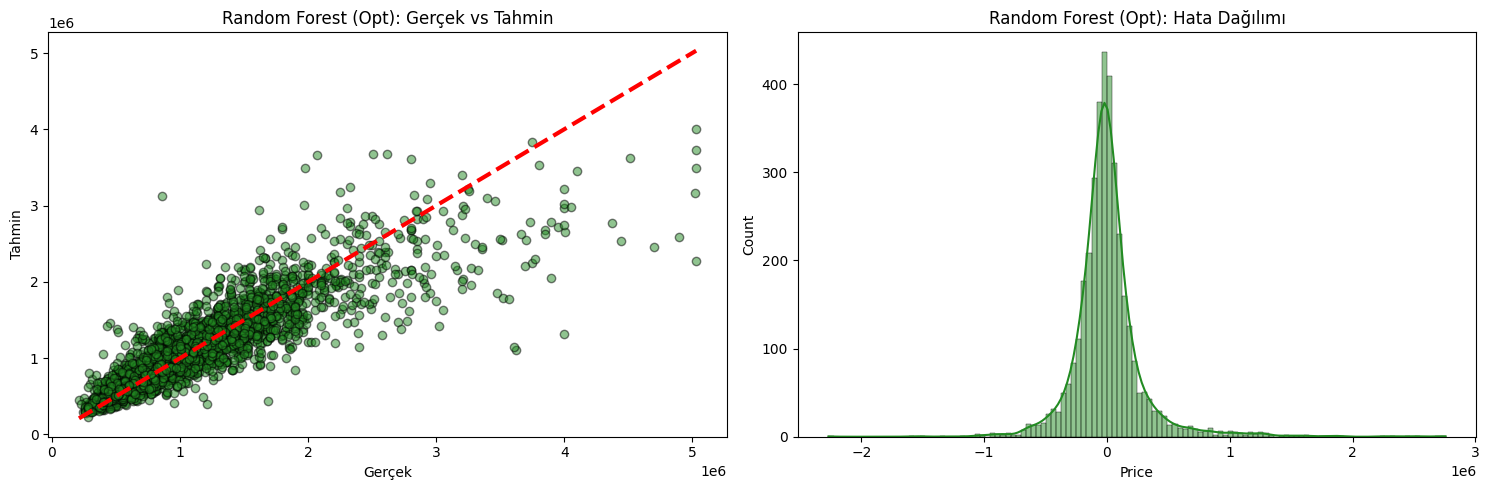


>>> 2. Gradient Boosting GridSearch

OPTIMIZED MODEL RAPORU: GRADIENT BOOSTING (OPT)
En İyi Parametreler: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}

┌─────────────────────────┬───────────────┐
│ Metrik                  │ Değer         │
├─────────────────────────┼───────────────┤
│ İşlem Süresi (sn)       │ 13.7501       │
│ R2 Score                │ 0.7901        │
│ MAE (Mutlak Hata)       │ 174277.68     │
│ RMSE (Karekök Hata)     │ 288600.85     │
└─────────────────────────┴───────────────┘



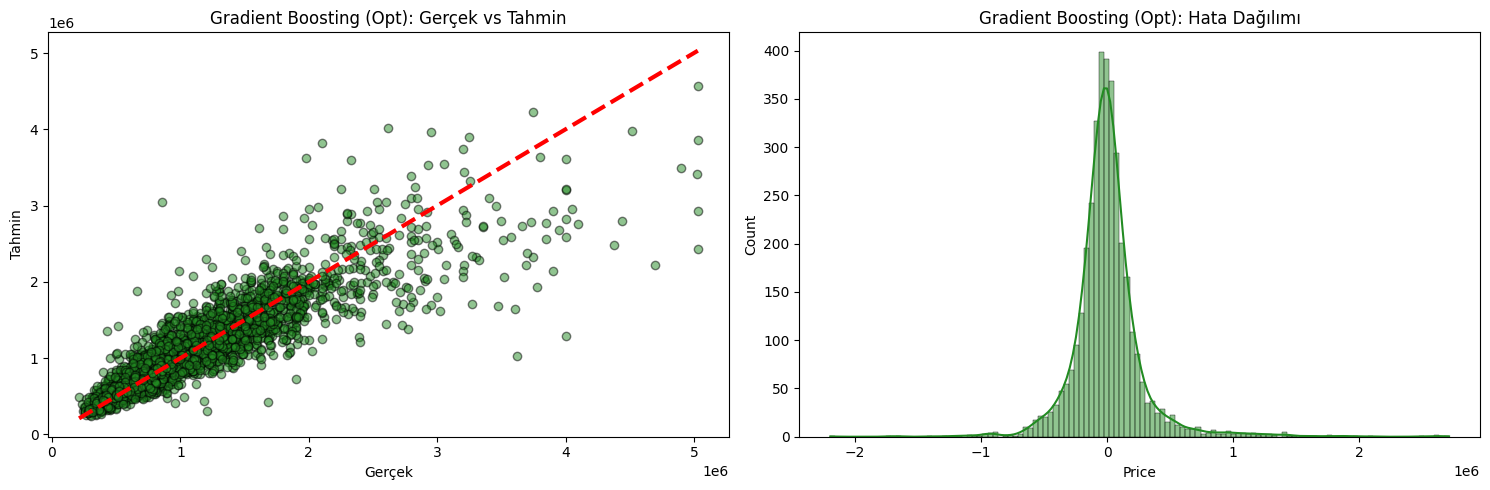


>>> 3. Ridge Regression GridSearch

OPTIMIZED MODEL RAPORU: RIDGE REGRESSION (OPT)
En İyi Parametreler: {'alpha': 10.0}

┌─────────────────────────┬───────────────┐
│ Metrik                  │ Değer         │
├─────────────────────────┼───────────────┤
│ İşlem Süresi (sn)       │ 0.1700        │
│ R2 Score                │ 0.6533        │
│ MAE (Mutlak Hata)       │ 245142.19     │
│ RMSE (Karekök Hata)     │ 370942.26     │
└─────────────────────────┴───────────────┘



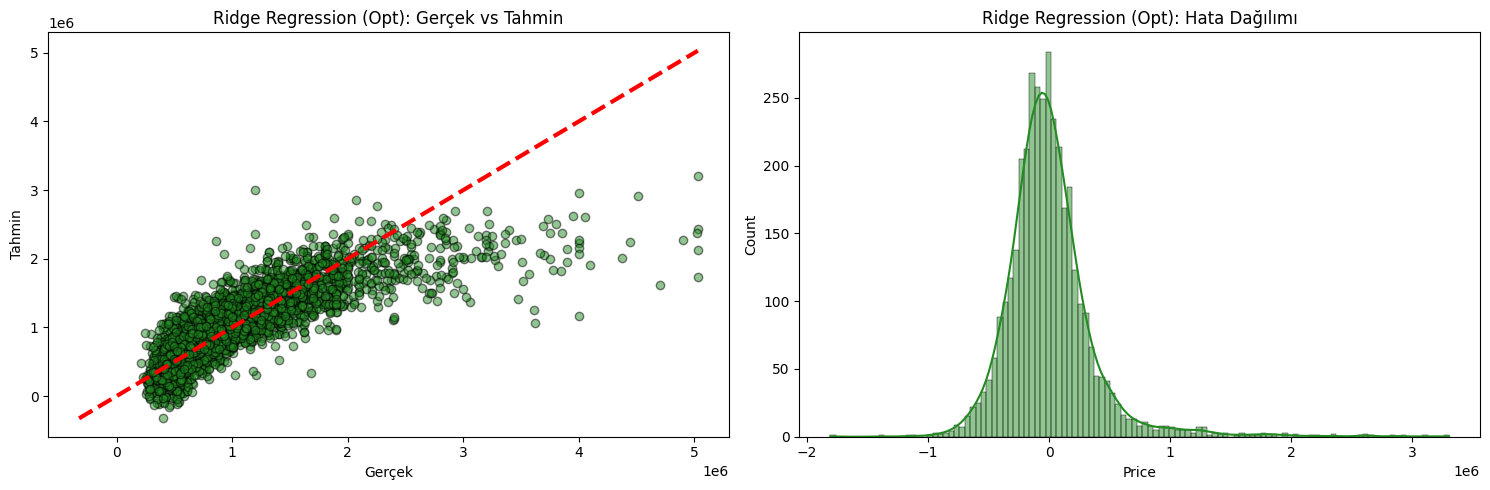


=== OPTİMİZE MODEL SONUÇLARI ===
                         R2 Score      RMSE       MAE  Süre
Gradient Boosting (Opt)      0.79 288600.85 174277.68 13.75
Random Forest (Opt)          0.78 295561.17 176801.93 21.48
Ridge Regression (Opt)       0.65 370942.26 245142.19  0.17


In [6]:
opt_results = {}

# Random Forest Optimizasyon
print(">>> 1. Random Forest GridSearch")
start = time.time()
grid_rf = GridSearchCV(RandomForestRegressor(random_state=42), 
                       {'n_estimators': [50, 100], 'max_depth': [10, 20, None]}, cv=3, n_jobs=-1)
grid_rf.fit(X_train_scaled, y_train)
evaluate_regression_performance("Random Forest (Opt)", grid_rf.best_estimator_, X_test_scaled, y_test, time.time()-start,
                                best_params=grid_rf.best_params_, result_dict=opt_results, plot_color='forestgreen')

# Gradient Boosting Optimizasyon
print("\n>>> 2. Gradient Boosting GridSearch")
start = time.time()
grid_gb = GridSearchCV(GradientBoostingRegressor(random_state=42), 
                       {'n_estimators': [100, 200], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5]}, cv=3, n_jobs=-1)
grid_gb.fit(X_train_scaled, y_train)
evaluate_regression_performance("Gradient Boosting (Opt)", grid_gb.best_estimator_, X_test_scaled, y_test, time.time()-start,
                                best_params=grid_gb.best_params_, result_dict=opt_results, plot_color='forestgreen')

# Ridge Regression (Linear için overfitting önleme)
print("\n>>> 3. Ridge Regression GridSearch")
start = time.time()
grid_ridge = GridSearchCV(Ridge(), {'alpha': [0.1, 1.0, 10.0]}, cv=5, n_jobs=-1)
grid_ridge.fit(X_train_scaled, y_train)
evaluate_regression_performance("Ridge Regression (Opt)", grid_ridge.best_estimator_, X_test_scaled, y_test, time.time()-start,
                                best_params=grid_ridge.best_params_, result_dict=opt_results, plot_color='forestgreen')

print("\n=== OPTİMİZE MODEL SONUÇLARI ===")
print(pd.DataFrame(opt_results).T.sort_values(by='R2 Score', ascending=False))

Hücre 7: Özellik Önemi (Feature Importance)


==================== RANDOM FOREST ÖZELLİK ANALİZİ ====================


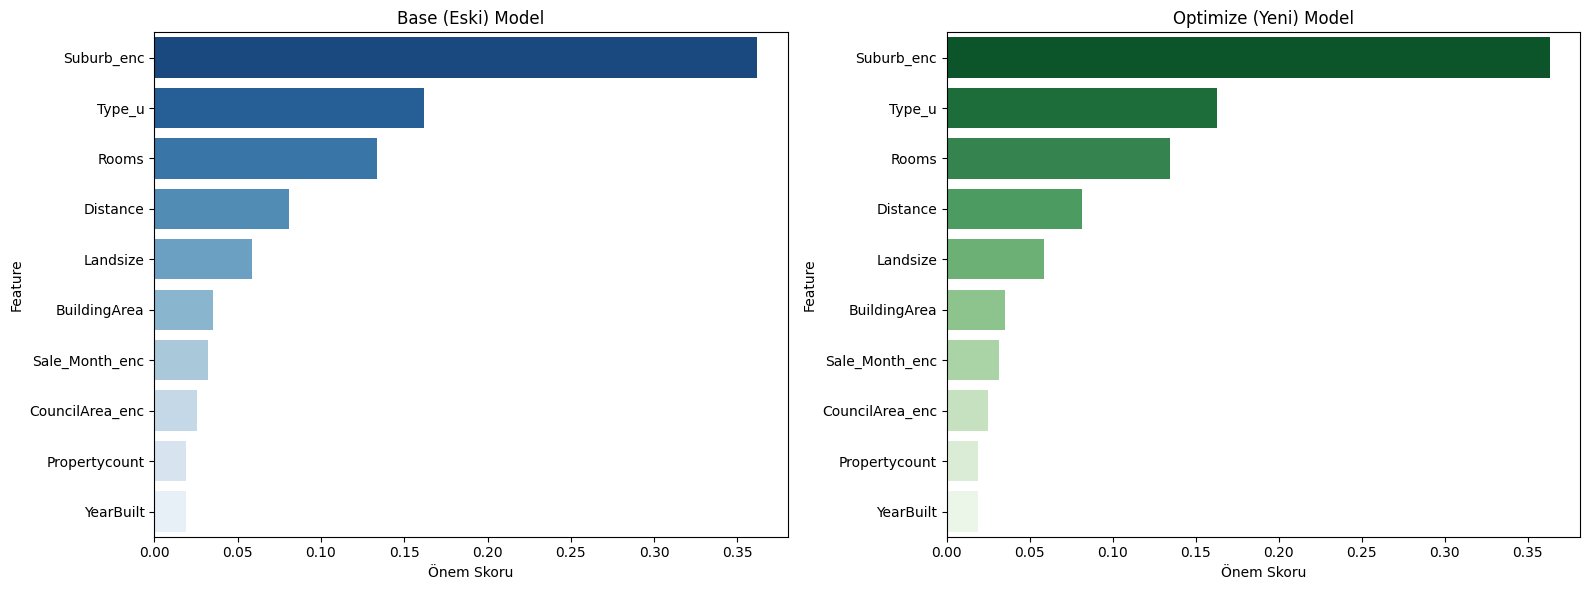


==================== GRADIENT BOOSTING ÖZELLİK ANALİZİ ====================


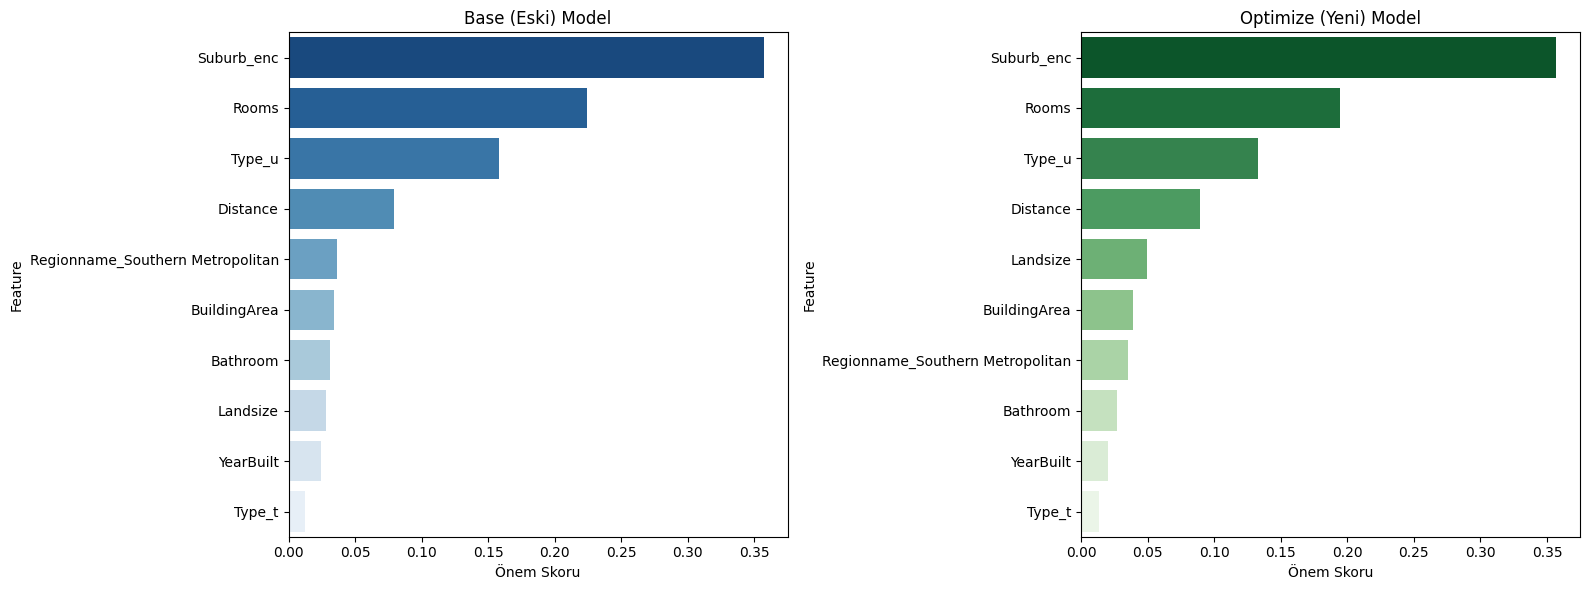


==================== LINEAR VS RIDGE ÖZELLİK ANALİZİ ====================


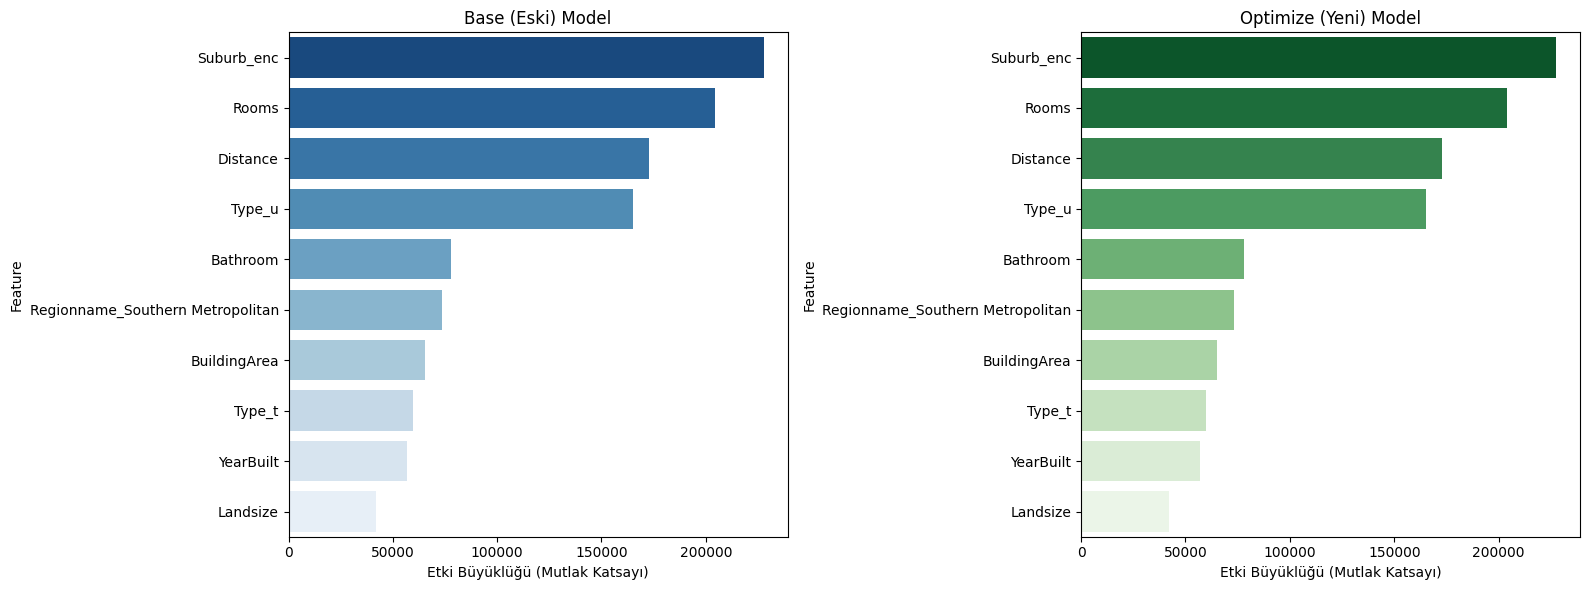

In [7]:


def plot_importance_comparison(model_name, base_model, opt_model, feature_names):

    print(f"\n{'='*20} {model_name.upper()} ÖZELLİK ANALİZİ {'='*20}")
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Modelleri Listele
    models = [
        (base_model, "Base (Eski) Model", axes[0], 'Blues_r'), 
        (opt_model, "Optimize (Yeni) Model", axes[1], 'Greens_r')
    ]
    
    for model, title, ax, palette in models:
        importances = None
        imp_label = "Önem Skoru"
        
        # 1. Durum: Ağaç Modelleri (Random Forest, Gradient Boosting)
        if hasattr(model, 'feature_importances_'):
            importances = model.feature_importances_
            
        # 2. Durum: Lineer Modeller (Linear Reg, Ridge) -> Katsayıları Mutlak Değere Çeviriyoruz
        elif hasattr(model, 'coef_'):
            importances = np.abs(model.coef_) # Negatifleri pozitife çevirelim etki büyüklüğünü görebilmek için
            imp_label = "Etki Büyüklüğü (Mutlak Katsayı)"
            
        if importances is not None:
            # Boyut eşleşmesi kontrolü
            if len(importances) != len(feature_names):
                print(f"UYARI: {title} sütun sayısı uyuşmazlığı. (Model: {len(importances)}, Veri: {len(feature_names)})")
                continue
            feat_df = pd.DataFrame({
                'Feature': feature_names,
                'Importance': importances
            }).sort_values(by='Importance', ascending=False).head(10) # En önemli 10
            
            # Çizim
            sns.barplot(x='Importance', y='Feature', data=feat_df, ax=ax, palette=palette)
            ax.set_title(f'{title}')
            ax.set_xlabel(imp_label)
        else:
            ax.text(0.5, 0.5, "Bu model özellik önemi sunmuyor.", ha='center')

    plt.tight_layout()
    plt.show()


# MODELLERİ ÇALIŞTIR VE ÇİZ



if 'X_train_scaled' in locals() and hasattr(X_train_scaled, 'columns'):

    feats = X_train_scaled.columns
else:

    if 'X_train_final' in locals():
        feats = X_train_final.columns
    else:
        
        feats = [f"Feature_{i}" for i in range(X_train_scaled.shape[1])]

# 1. Random Forest Kıyaslama
if 'rf' in locals() and 'grid_rf' in locals():
    plot_importance_comparison("Random Forest", rf, grid_rf.best_estimator_, feats)

# 2. Gradient Boosting Kıyaslama
if 'gb_reg' in locals() and 'grid_gb' in locals():
    plot_importance_comparison("Gradient Boosting", gb_reg, grid_gb.best_estimator_, feats)

# 3. Linear Regression vs Ridge Kıyaslama
if 'lr' in locals() and 'grid_ridge' in locals():
    plot_importance_comparison("Linear vs Ridge", lr, grid_ridge.best_estimator_, feats)